# Observation-size control for the corpus-atlas candidates (2026-10-21)

Question: do the seven candidates A–G of the [selection notebook](zenodo_1053_tsne_261021.ipynb) survive a control for observation size, the number of processes M and of samples T? Co-location should mean a shared dependence-organisation signature, not a shared recording size. Some candidates come from one UEA source at one size (A: NATOPS, 24 × 51; most of D: Cricket, 6 × 1197), so source and size are aliased there and no observational control can separate them completely.

Design. Three controls, because in this archive size is close to a source label (section 1) and no one control suffices:
1. *Remove a smooth size component.* Subtract a quadratic surface in (log M, log T) from the full-rank scores, then re-measure each candidate with membership fixed (silhouette) and refitted (best-match Jaccard of a new Ward-40). The primary version estimates the surface only from variation within parent recordings, the closest available case of "same dynamics, different size"; within-source estimation is the sensitivity. A pooled regression is the over-control bound: where size is aliased with source it also removes source character, and it cannot separate a source whose size is unique. A placebo repeats each procedure 50 times with (M, T) shuffled within the same grouping, to calibrate how much any such removal perturbs Ward. This control removes a shared mean shift only.
2. *Size-matched null sets* (primary test). For each candidate, 1,000 same-size sets drawn from other source families, each member replaced by one of its five nearest other-source rows in standardised (log M, log T). They share the candidate's estimation regime and z's noise level without sharing its sources. Matched sets also inherit whatever the few sources at those sizes have in common, so the result is a lower bound on the separation that size does not explain.
3. *One parent at several sizes.* New time-prefix crops would need pyspi. The probe instead uses the 58 parent recordings already present at several sizes (all synthetic generators): how far z moves, and whether candidate membership holds, when only M or T changes. Real sources present at several sizes (NetSim, PEMS-SF, TestWEATH) give a within-source check.

Fixed inputs: the cached tsne-261021 full-rank geometry (21,788 features, distances equal to the full feature space) and its Ward-40 partition; nothing here re-selects candidates. Code: `research/zenodo/atlas/mt_control.py` (tests in `research/zenodo/atlas/tests/test_mt_control.py`). No pyspi is run.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from matplotlib import patheffects
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import silhouette_samples

from research.zenodo.atlas import mt_control as mc
from research.zenodo.atlas import tsne_atlas as ta
%matplotlib inline

ta.notebook_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
config = yaml.safe_load(ta.CONFIG.read_text())
OUT = ROOT / config["output"]
FIGURES = OUT / "figures"
R = ta.load(OUT)  # cached by `python -m research.zenodo.atlas.tsne_atlas`
corpus = ta.load_corpus(config)
meta, A = corpus["meta"], R["arrays"]
assert (meta.dataset.to_numpy() == A["names"]).all()
labels, scores, D = A["partition__ward40"], A["scores_primary"], A["full_distances"]
mc.check_candidates(meta, labels)
xy = A["map__primary-p30-x1-pca"][0]
LETTERS = list(mc.CANDIDATES.values())
members = {letter: np.flatnonzero(labels == c) for c, letter in mc.CANDIDATES.items()}
silhouette = silhouette_samples(D, labels, metric="precomputed")
print(f"{len(meta)} recordings · {meta.parent.nunique()} parents · M {meta.M.min()}–{meta.M.max()} · T {meta['T'].min()}–{meta['T'].max()}")

1053 recordings · 688 parents · M 5–29 · T 30–3000


## 1. How size is laid out in the archive

In [2]:
cell_sources = meta.groupby(["M", "T"]).source.nunique()
own_cell = meta.set_index(["M", "T"]).index.map(cell_sources).to_numpy() == 1
print(f"{own_cell.mean():.0%} of recordings share their exact (M, T) only with their own source family.")
logM, logT = np.log(meta.M.to_numpy(float)), np.log(meta["T"].to_numpy(float))
rows = []
for letter, rows_in in members.items():
    sources = meta.source[rows_in].unique()
    other = ~meta.source.isin(sources).to_numpy()
    near = [np.sum(other & (np.abs(logM - logM[i]) <= np.log(1.25)) & (np.abs(logT - logT[i]) <= np.log(1.25))) for i in rows_in]
    exact = [np.sum(other & (meta.M.to_numpy() == meta.M[i]) & (meta["T"].to_numpy() == meta["T"][i])) for i in rows_in]
    m, t = meta.M[rows_in], meta["T"][rows_in]
    rows.append({"letter": letter, "M": f"{m.min()}–{m.max()}", "T": f"{t.min()}–{t.max()}", "T/M": f"{(t / m).min():.1f}–{(t / m).max():.0f}",
                 "other-source rows at the same (M, T), median": np.median(exact),
                 "within ×1.25 in M and T, median": np.median(near)})
pd.DataFrame(rows).set_index("letter")

57% of recordings share their exact (M, T) only with their own source family.


,M,T,T/M,"other-source rows at the same (M, T), median","within ×1.25 in M and T, median"
letter,,,,,
A,24–24,51–51,2.1–2,0.0,27.0
B,5–10,2000–2000,200.0–400,24.0,32.0
C,5–20,100–1000,5.0–200,11.0,30.0
D,6–9,134–1197,14.9–200,0.0,70.0
E,5–29,144–2000,5.0–400,0.0,16.0
F,6–25,100–3000,6.2–500,0.0,8.0
G,5–20,100–2000,5.0–400,16.0,44.0


z is a Pearson correlation over the M(M−1) ordered off-diagonal entries of two MPIs, so its sampling noise should fall as M grows. The check below reads that off the full feature space: each recording's mean distance to its five nearest neighbours, by M, over the whole corpus and within the synthetic generator grid (the same generators run at M = 5, 10, 20).

In [3]:
nn5 = np.sort(D + np.diag(np.full(len(D), np.inf)), axis=1)[:, :5].mean(axis=1)
grid_sources = ["VAR", "VMA", "IID noise", "Oscillator sync", "CML"]
in_grid = meta.source.isin(grid_sources).to_numpy()
bins = pd.cut(meta.M, [4, 6, 10, 16, 21, 29])
nn5_series = pd.Series(nn5, index=meta.index)
precision = pd.DataFrame({"all recordings": nn5_series.groupby(bins, observed=False).median(), "n": bins.value_counts().sort_index(),
                          "generator grid": nn5_series[in_grid].groupby(bins[in_grid], observed=False).median()})
rho_M, rho_T = spearmanr(meta.M, nn5)[0], spearmanr(meta["T"], nn5)[0]
print(f"5-NN distance vs M: Spearman {rho_M:.2f}; vs T: {rho_T:.2f}. Generator grid alone vs M: {spearmanr(meta.M[in_grid], nn5[in_grid])[0]:.2f}")
precision.round(1)

5-NN distance vs M: Spearman -0.83; vs T: 0.11. Generator grid alone vs M: -0.85


,all recordings,n,generator grid
M,,,
"(4, 6]",43.0,408,45.4
"(6, 10]",30.1,280,26.8
"(10, 16]",27.0,109,NaN
"(16, 21]",20.7,127,18.1
"(21, 29]",21.0,129,NaN


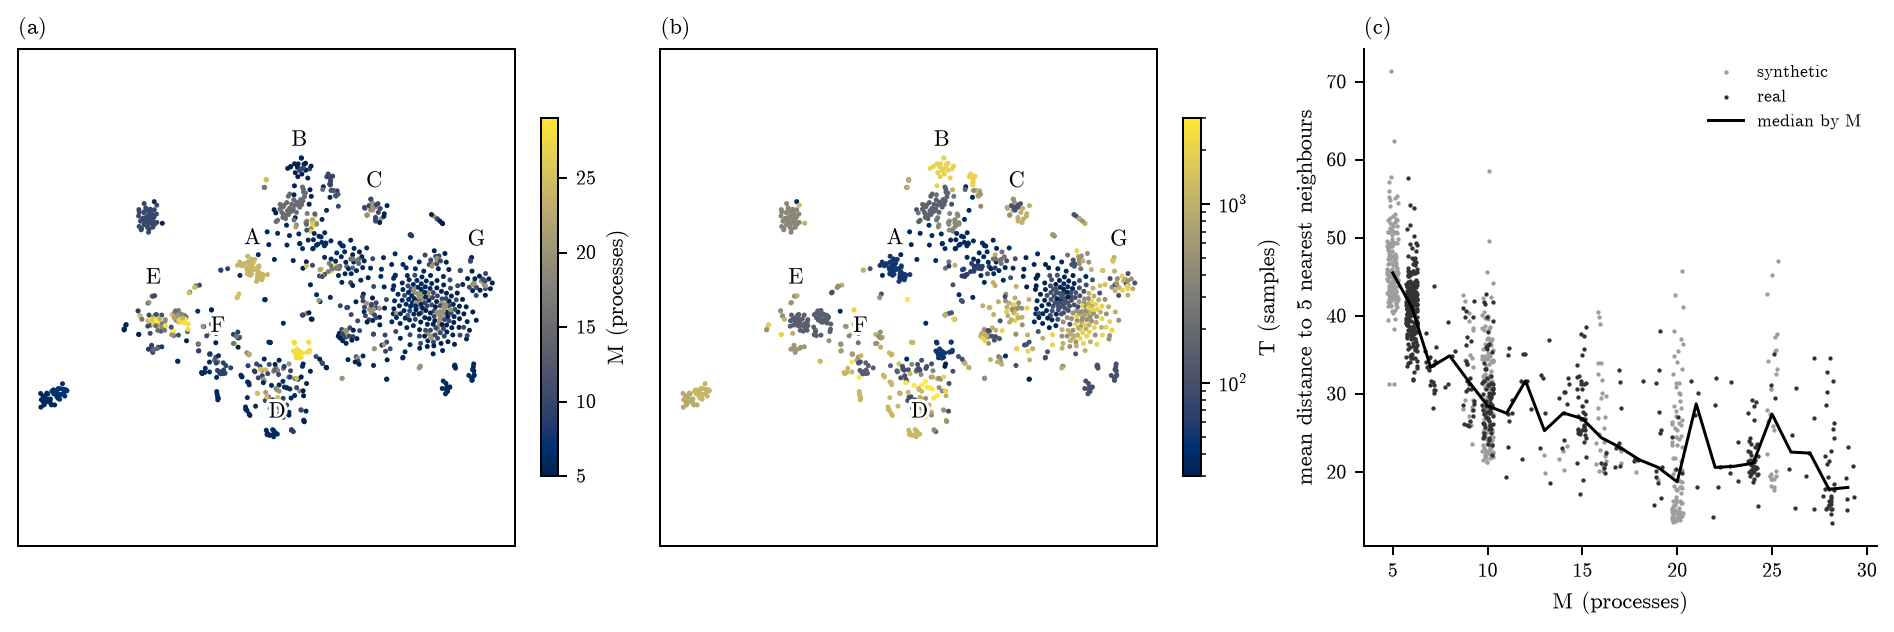

In [4]:
def size_map(ax, values, label, norm=None):
    order = np.random.default_rng(1729).permutation(len(xy))
    sc = ax.scatter(*xy[order].T, c=np.asarray(values)[order], cmap="cividis", norm=norm, s=4, linewidths=0, rasterized=True)
    for letter, rows_in in members.items():
        ax.annotate(letter, (xy[rows_in, 0].mean(), xy[rows_in, 1].max()), xytext=(0, 3), textcoords="offset points", ha="center",
                    va="bottom", fontsize=9, path_effects=[patheffects.withStroke(linewidth=2.5, foreground="white")])
    lo, hi = xy.min(axis=0), xy.max(axis=0)
    mid, radius = (lo + hi) / 2, float(np.max(hi - lo)) * .55
    ax.set(xlim=(mid[0] - radius, mid[0] + radius), ylim=(mid[1] - radius, mid[1] + radius), xticks=[], yticks=[], aspect="equal")
    ax.spines[["top", "right"]].set_visible(True)
    plt.colorbar(sc, ax=ax, shrink=.72, label=label)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
size_map(axes[0], meta.M, "M (processes)")
size_map(axes[1], meta["T"], "T (samples)", LogNorm())
jitter = np.random.default_rng(0).uniform(-.3, .3, len(meta))
for origin, colour in [("synthetic", "0.62"), ("real", "0.2")]:
    pick = (meta.origin == origin).to_numpy()
    axes[2].scatter(meta.M[pick] + jitter[pick], nn5[pick], s=3, c=colour, linewidths=0, label=origin, rasterized=True)
median = pd.Series(nn5).groupby(meta.M).median()
axes[2].plot(median.index, median.to_numpy(), color="k", lw=1.2, label="median by M")
axes[2].set(xlabel="M (processes)", ylabel="mean distance to 5 nearest neighbours")
axes[2].legend(fontsize=7, loc="upper right")
for ax, tag in zip(axes, "abc"):
    ax.set_title(f"({tag})", loc="left", fontsize=9)
for ext in ["svg", "pdf", "png"]:
    fig.savefig(FIGURES / f"mt-control-size.{ext}", dpi=600 if ext == "png" else None)
plt.show()

**Size is nearly a source label, and M sets the precision of z.** 57% of recordings share their exact (M, T) only with their own source family, and for A, D, E and F the median member has no other-source recording at its exact size (A's nearest are FingerMovements EEG, 28 × 50, and FaceDetection MEG, M × 62). Size enters the geometry mainly through precision rather than location: the mean distance to the five nearest neighbours falls from 43 at M ≤ 6 to 21 at M ≥ 17 (Spearman −0.83; −0.85 within the generator grid, where the same generators run at each M), while T barely matters (0.11). This is the pattern expected from the sampling error of a correlation over M(M−1) entries (inferred; the entries are not independent, so the effective count is smaller). Two consequences: large-M groups look tighter in the full space than small-M groups of equal character, so silhouettes are comparable only against size-matched references (section 3); and A's high silhouette is partly its M = 24. Panels (a, b): the maps carry broad M and T gradients (the synthetic grid's M = 5 rows dominate the large right-hand region), but the candidates sit at mixed sizes except where their source has one size.

## 2. Control 1: remove a smooth size component

In [5]:
residual, removed = mc.residual_controls(scores, meta, labels, placebo=50)
removed[["control", "removed_share", "placebo_removed_share", "within_r2", "M_support", "T_support", "varying_groups", "varying_rows"]].round(4)

,control,removed_share,placebo_removed_share,within_r2,M_support,T_support,varying_groups,varying_rows
0,parent,0.0167,0.0066,0.0344,"(5, 25)","(100, 2001)",58.0,422.0
1,source,0.0201,0.0094,0.0105,"(5, 29)","(62, 2001)",25.0,623.0
2,pooled,0.0599,0.0048,NaN,"(5, 29)","(30, 3000)",NaN,NaN


In [6]:
hennig = R["clusters"].query("partition == 'ward40'").set_index("cluster").jaccard_mean
table = residual.set_index(["letter", "control"])[["silhouette", "jaccard", "placebo_jaccard_median", "placebo_jaccard_q05"]].unstack("control")
table = table.reindex(columns=["parent", "source", "pooled"], level=1)
table.insert(0, ("original", "Hennig jaccard"), [hennig[c] for c in mc.CANDIDATES])
table.insert(0, ("original", "silhouette"), [silhouette[rows_in].mean() for rows_in in members.values()])
table.round(2)

original                silhouette               jaccard               placebo_jaccard_median               placebo_jaccard_q05              
control silhouette Hennig jaccard     parent source pooled  parent source pooled                 parent source pooled              parent source pooled
letter                                                                                                                                                 
A             0.31           0.98       0.31   0.31   0.27    0.95   0.95   1.00                   1.00   0.95   1.00                0.95   0.95   0.97
B             0.12           0.90       0.12   0.13   0.09    0.91   0.91   0.91                   0.95   0.95   0.91                0.91   0.91   0.85
C             0.14           0.77       0.13   0.12   0.10    0.92   0.92   0.92                   1.00   0.84   0.76                0.60   0.52   0.60
D             0.14           0.85       0.14   0.15   0.14    1.00   1.00   1.00                   1.00   1.00   1.00                0.65   0.58   0.57
E             0.10           0.72       0.09   0.10   0.10    0.98   0.81   0.71                   0.83   1.00   0.98                0.69   0.44   0.69
F             0.04           0.76       0.04   0.05   0.03    0.63   0.55   0.32                   0.87   0.87   0.84                0.61   0.55   0.52
G             0.05           0.90       0.05   0.05   0.03    1.00   0.97   0.97                   0.97   0.97   0.97                0.94   0.94   0.92

**A smooth size component is small, and removing it dissolves no candidate.** The pooled quadratic surface explains 6.0% of full-space variance (placebo 0.5%). The within-parent surface explains 3.4% of within-parent variance and, applied to every row, removes 1.7% of the total (placebo 0.7%). With membership fixed, silhouettes barely move under the parent and source controls (every change ≤ 0.02; A stays at 0.31); the pooled over-control lowers them by up to 0.04 (A, B, C, G). Under the parent and source controls the refitted Ward-40 recovers every candidate at or above the 5th percentile of its placebo, so Jaccard below 1 there is Ward boundary noise, which the placebo shows is large for C–F (q05 0.44–0.69). F is the exception in degree: at the parent control it sits at its placebo q05 (0.63 vs 0.61; placebo median 0.87), and under the pooled over-control it falls below (0.32 vs 0.52). E under the pooled over-control is at its q05 (0.71 vs 0.69). F's reading (trending, near-integrated series, whose accumulated trend grows with window length) predicts that its boundary aligns with size-correlated directions, so this is not separable from its character in this archive. Caveat: the parent surface is estimated on synthetic generators at T ≥ 100, so A (T = 51) lies outside its support and receives the T = 100 correction, an under-correction if size effects grow below T = 100.

## 3. Control 2: size-matched sets from other sources

In [7]:
null, draws = mc.matched_null(D, labels, meta, replicates=1000)
null.set_index("letter").round(3)

,silhouette,matched_mean,matched_q95,random_mean,p_matched,survival,match_M_ratio,match_T_ratio,rank_matched,rank_outsiders,matched_sources
letter,,,,,,,,,,,
A,0.310,-0.010,0.056,-0.320,0.001,0.508,1.167,1.020,2.0,6.0,FingerMovements 20; FaceDetection 4
B,0.118,-0.292,-0.252,-0.320,0.001,0.935,1.000,1.000,30.0,30.0,VMA 12; VAR 12; Mouse fMRI 10; …
C,0.139,0.001,0.053,-0.327,0.001,0.296,1.000,1.000,23.0,22.0,VMA 42; IID noise 34; TestCLIM 6
D,0.140,-0.272,-0.229,-0.320,0.001,0.894,1.000,1.336,33.5,29.0,SelfRegulationSCP1 19; ArticularyWordRecognition 14; Kuramoto–Sakaguchi 6; …
E,0.097,-0.255,-0.229,-0.311,0.001,0.862,1.053,1.056,23.0,24.0,Oscillator sync 38; UCLA fMRI 37; NetSim fMRI 19; …
F,0.039,-0.398,-0.380,-0.324,0.001,1.203,1.000,1.336,10.0,17.0,SelfRegulationSCP1 19; Kuramoto–Sakaguchi 18; Oscillator sync 16; …
G,0.048,-0.259,-0.221,-0.330,0.001,0.812,1.000,1.000,6.0,17.0,VMA 68; VAR 67; CML 45; …


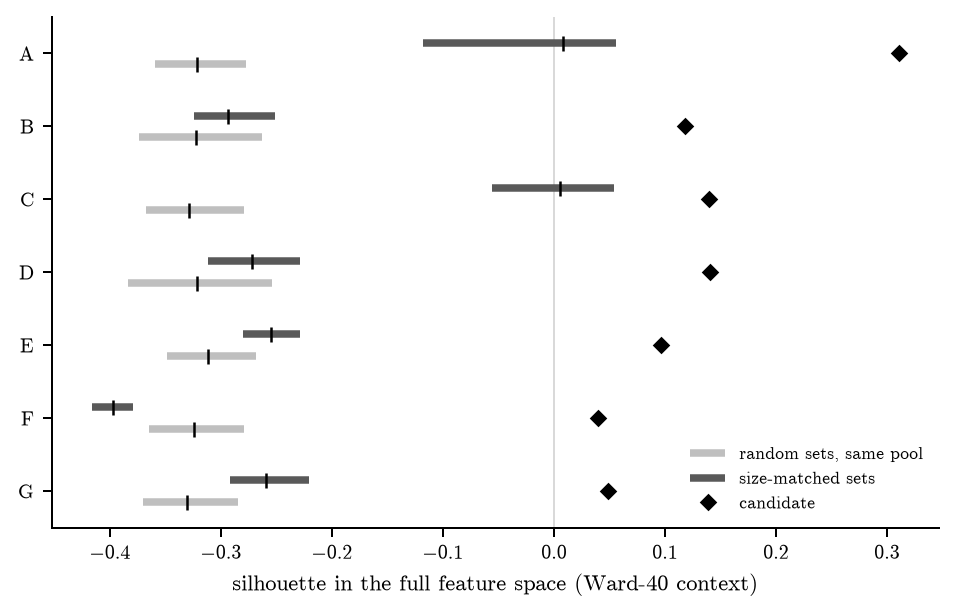

Bars: 5–95% of 1,000 sets; tick: median.


In [8]:
fig, ax = plt.subplots(figsize=(5.2, 3.3))
for y, letter in enumerate(LETTERS):
    d = draws[letter]
    for values, colour, offset, name in [(d["random"], "0.75", .15, "random sets, same pool"), (d["matched"], "0.35", -.15, "size-matched sets")]:
        lo, mid, hi = np.quantile(values, [.05, .5, .95])
        ax.plot([lo, hi], [y + offset] * 2, color=colour, lw=3, solid_capstyle="butt", label=name if y == 0 else None)
        ax.plot(mid, y + offset, "|", color="k", ms=6)
    ax.plot(d["observed"], y, "D", color="k", ms=4, label="candidate" if y == 0 else None)
ax.axvline(0, color="0.85", lw=.8, zorder=0)
ax.set(yticks=range(len(LETTERS)), yticklabels=LETTERS, xlabel="silhouette in the full feature space (Ward-40 context)", ylim=(len(LETTERS) - .5, -.5))
ax.legend(fontsize=7, loc="lower right")
for ext in ["svg", "pdf", "png"]:
    fig.savefig(FIGURES / f"mt-control-null.{ext}", dpi=600 if ext == "png" else None)
plt.show()
print("Bars: 5–95% of 1,000 sets; tick: median.")

**Every candidate is more separated than all 1,000 of its size-matched sets** (p = 0.001, the resolution of the test). For B, D, E, F and G the size-matched sets are about as diffuse as random sets (survival 0.81–1.20; above 1 means matched sets are *less* cohesive than random ones), so size explains little of their separation. Two candidates keep half or less of their margin, for different reasons:
- **C** (survival 0.30). Its size-matched rows come from the generator grid (VMA, IID noise, TestCLIM at M 5–20, T 100–1,000), which is itself a broad, cohesive region (the 149-member weak-coupling group). Those rows are not drawn toward C (they rank C 23rd of the 39 other clusters, all outsiders 22nd), so the matched-set cohesion belongs to the grid, not to proximity to C.
- **A** (survival 0.51). Its size-matched rows are all 20 FingerMovements recordings and FaceDetection rows. They rank A as their 2nd-nearest cluster (all outsiders: 6th), so A's *neighbourhood* is size-associated. The next cells ask whether that is size or real-data character.

`rank_*` is the position of the candidate among the clusters other than a row's own, by mean distance (1 = nearest); being scale-free per row, it is not driven by how noisy that row's z is. `matched_sources` lists the sources of each member's five nearest other-source rows; when those are exhausted the draw widens to the next nearest, which `match_M_ratio` and `match_T_ratio` (median member-to-match ratios) summarise.

In [9]:
rank = mc.other_cluster_rank(D, labels)
size_probe = []
for source in ["FingerMovements", "FaceDetection", "Heartbeat", "PEMS-SF", "LSST", "RacketSports", "BasicMotions", "UCLA fMRI"]:
    r = np.flatnonzero((meta.source == source).to_numpy())
    rho, p = spearmanr(meta.M[r], rank[r, 35]) if meta.M[r].nunique() > 1 else (np.nan, np.nan)
    size_probe.append({"source": source, "M": f"{meta.M[r].min()}–{meta.M[r].max()}", "T": int(meta["T"][r].iloc[0]), "n": len(r),
                       "median rank of A": np.median(rank[r, 35]), "share ranking A in top 3": np.mean(rank[r, 35] <= 3),
                       "Spearman(M, rank of A)": rho, "p": p})
print(f"All {np.sum(labels != 35)} outsiders: median rank of A {np.median(rank[labels != 35, 35]):.0f}; share ranking A in top 3 {np.mean(rank[labels != 35, 35] <= 3):.2f}")
fm = np.flatnonzero((meta.source == "FingerMovements").to_numpy())
fm_cluster = np.bincount(labels[fm]).argmax()
print(f"FingerMovements: Ward cluster {fm_cluster} holds {np.sum(labels[fm] == fm_cluster)} of its {len(fm)} rows plus "
      f"{np.sum(labels == fm_cluster) - np.sum(labels[fm] == fm_cluster)} other; cluster silhouette {silhouette[labels == fm_cluster].mean():.2f}")
outside = labels != 35
for name, pick in [("real outsiders", outside & (meta.origin == "real").to_numpy()), ("generator-grid outsiders", outside & in_grid)]:
    by_m = pd.Series(rank[pick, 35]).groupby(pd.cut(meta.M[pick].to_numpy(), [4, 6, 10, 16, 21, 29]), observed=True).median()
    print(f"{name}, median rank of A by M:", {str(k): v for k, v in by_m.items()})
pd.DataFrame(size_probe).set_index("source").round(2)

All 1017 outsiders: median rank of A 6; share ranking A in top 3 0.26
FingerMovements: Ward cluster 11 holds 20 of its 20 rows plus 1 other; cluster silhouette 0.31
real outsiders, median rank of A by M: {'(4, 6]': 7.0, '(6, 10]': 4.0, '(10, 16]': 3.0, '(16, 21]': 3.0, '(21, 29]': 3.0}
generator-grid outsiders, median rank of A by M: {'(4, 6]': 12.0, '(6, 10]': 11.0, '(16, 21]': 11.0}


,M,T,n,median rank of A,share ranking A in top 3,"Spearman(M, rank of A)",p
source,,,,,,,
FingerMovements,28–28,50,20,2.0,0.80,NaN,NaN
FaceDetection,10–29,62,20,3.0,0.80,-0.16,0.49
Heartbeat,10–28,405,18,2.0,0.94,-0.62,0.01
PEMS-SF,10–29,144,57,4.0,0.49,-0.03,0.82
LSST,6–6,36,80,5.0,0.42,NaN,NaN
RacketSports,6–6,30,38,10.0,0.00,NaN,NaN
BasicMotions,6–6,100,39,10.0,0.00,NaN,NaN
UCLA fMRI,15–15,152,37,2.0,0.86,NaN,NaN


In [10]:
descriptors = pd.DataFrame([ta.raw_descriptors(corpus["arrays"][n]) for n in meta.dataset])
pick = meta.source.isin(["NATOPS", "FingerMovements", "FaceDetection"]).to_numpy()
print("Raw-series medians (as in the selection notebook):")
display(descriptors[pick].groupby(meta.source[pick].to_numpy()).median().round(2))
x_primary, _ = ta.preprocess(corpus["raw"], "primary")
probes = {s: np.flatnonzero((meta.source == s).to_numpy()) for s in ["FingerMovements", "FaceDetection"]}
drop = mc.family_drop(x_primary, corpus["pairs"][A["keep_indices"]], corpus["spis"], labels,
                      {s: ta.spi_category(s) for s in corpus["spis"]}, 35, probes)
drop.set_index("removed").round(3)

Raw-series medians (as in the selection notebook):


,lag1,trend_r2,negative_share_strong,pc1_share,repeat_fraction,max_robust_z
FaceDetection,0.32,0.03,0.37,0.28,0.0,5.16
FingerMovements,0.64,0.19,0.48,0.28,0.0,12.82
NATOPS,0.96,0.07,0.12,0.61,0.0,8.68


,features,silhouette,jaccard,rank_FingerMovements,rank_FaceDetection,rank_outsiders
removed,,,,,,
none,21788,0.310,1.000,2.0,3.0,6.0
"precision (prec, prec-sq)",20176,0.309,1.000,2.5,3.0,7.0
basic,10030,0.261,0.565,2.0,2.0,4.0
causal,21568,0.310,1.000,2.0,3.0,6.0
distance,16378,0.341,1.000,2.0,2.5,6.0
infotheory,17159,0.293,1.000,2.0,3.0,7.0
misc,18066,0.344,1.000,2.0,3.0,7.0
spectral,9576,0.303,1.000,2.0,4.0,9.0


**A's adjacency is to real multichannel recordings rather than to its size regime, and its separation does not rest on the precision estimators.** FingerMovements forms its own Ward cluster (all 20 rows plus one oscillator window; silhouette 0.31, as distinct as A), adjacent to A. A is a near cluster for real outsiders with M ≥ 10 in general (median rank 3; Heartbeat at T = 405 and UCLA fMRI at T = 152 rank it 2nd), whereas the synthetic grid ranks it 11th–12th at every M. Within fixed-T sources, larger M brings rows closer to A only in Heartbeat (Spearman −0.62); FaceDetection and PEMS-SF show no trend. The size-matched sources also differ from NATOPS in raw character (lag-1 0.64 and 0.32 vs 0.96; first-PC share 0.28 vs 0.61). Removing all 1,612 precision-estimator pairs leaves A unchanged (silhouette 0.309, Jaccard 1.00) and the adjacency intact (rank 2.5), and no single SPI category carries the adjacency. The selection notebook's caveat, that T ≈ 2M near-singular precision estimates explain part of A's identity, is therefore not supported: the precision contrasts are real, but A holds without them. A does depend on pairs involving basic statistics (about half of all features; without them silhouette 0.26, Jaccard 0.57).

## 4. Control 3: one parent recording at several sizes

In [11]:
pairs = mc.parent_pairs(D, meta, labels)
summary = lambda g: g.agg(pairs=("distance", "size"), relative_distance=("relative", "median"), same_cluster=("same_cluster", "mean"))
display(summary(pairs.groupby("kind")).round(2))
t_only = pairs[pairs.kind == "T only"]
display(summary(t_only.groupby(pd.cut(t_only.T_ratio, [1, 2.5, 6, 12, 25]), observed=True)).round(2))
m_only = pairs[pairs.kind == "M only"]
display(summary(m_only.groupby(pd.cut(m_only.M_ratio, [1, 2.1, 3.1, 5.1]), observed=True)).round(2))
print("relative_distance: pair distance over the mean of the two recordings' 5-NN distances (1 = as close as a typical near neighbour).")
print("Parents with size variants:", pairs[pairs.kind.isin(["T only", "M only", "M and T"])].source.value_counts().to_dict())

,pairs,relative_distance,same_cluster
kind,,,
M and T,871,1.42,0.74
M only,366,1.31,0.82
T only,457,1.30,0.78
same size,7,1.04,1.00
transform,11,1.98,0.00


,pairs,relative_distance,same_cluster
T_ratio,,,
"(1.0, 2.5]",151,1.17,0.89
"(2.5, 6.0]",164,1.29,0.74
"(6.0, 12.0]",92,1.36,0.68
"(12.0, 25.0]",50,1.38,0.72


,pairs,relative_distance,same_cluster
M_ratio,,,
"(1.0, 2.1]",267,1.23,0.84
"(2.1, 3.1]",19,1.22,0.84
"(3.1, 5.1]",80,1.49,0.72


relative_distance: pair distance over the mean of the two recordings' 5-NN distances (1 = as close as a typical near neighbour).
Parents with size variants: {'VMA': 352, 'VAR': 342, 'IID noise': 287, 'Oscillator sync': 267, 'CML': 140, 'Kuramoto–Sakaguchi': 108, 'Brownian motion': 43, 'Epidemic incidence': 39, 'Ornstein–Uhlenbeck': 36, 'Wave 1D': 36, 'LEGION': 19, 'Wave 2D': 15, 'Van der Pol': 7, 'Wilson–Cowan': 3}


In [12]:
membership = mc.parent_membership(meta, labels)
display(membership)
from sklearn.metrics import roc_auc_score
cluster_of = {letter: c for c, letter in mc.CANDIDATES.items()}
split = []
for letter, source in [("B", "NetSim fMRI"), ("E", "PEMS-SF"), ("C", "TestWEATH"), ("G", "TestWEATH"), ("D", "Cricket"), ("F", "Cricket")]:
    r = np.flatnonzero((meta.source == source).to_numpy())
    inside = labels[r] == cluster_of[letter]
    sizes = meta.loc[r, ["M", "T"]].astype(str).agg("×".join, axis=1)
    auc = {v: roc_auc_score(inside, meta.loc[r, v]) if meta.loc[r, v].nunique() > 1 else np.nan for v in ["M", "T"]}
    split.append({"letter": letter, "source": source, "inside": f"{inside.sum()}/{len(r)}", "sizes": sizes.nunique(),
                  "AUC of M": auc["M"], "AUC of T": auc["T"],
                  "inside by size": "; ".join(f"{k} {g.sum()}/{len(g)}" for k, g in pd.Series(inside).groupby(sizes.to_numpy())) if sizes.nunique() <= 4 else "–"})
tw = meta.source == "TestWEATH"
print("TestWEATH: rows carrying 999 codes ('miss') by T:", meta[tw].groupby("T").dataset.apply(lambda n: f"{n.str.contains('miss').sum()}/{len(n)}").to_dict())
pd.DataFrame(split).set_index("letter").round(2)

,letter,parent,source,sizes_in,sizes,lost (M×T)
0,C,spatiotemporal_intermittency_ii_alpha-1-75_epsilon-0-3,CML,4,4,–
1,C,pattern_selection_alpha-1-71_epsilon-0-4,CML,5,5,–
2,C,spatiotemporal_chaos_alpha-2-0_epsilon-0-3,CML,5,5,–
3,C,oscillator_sync_k-4_conn_all,Oscillator sync,1,9,"20×501, 20×101, 10×1001, 10×501, 5×2001, 5×1001, 5×501, 5×101"
4,C,var_d-0.1_asymmetric_acf-high,VAR,1,11,"5×500, 5×1000, 5×2000, 10×100, 10×500, 10×1000, 10×2000, 20×100, 20×500, 20×1000"
5,E,oscillator_legion_stim-split_conn-bidir_params-1,LEGION,3,6,"5×2000, 5×1001, 5×501"
6,E,oscillator_legion_stim-rsplit_conn-bidir_params-1,LEGION,3,3,–
7,E,brownian_geometric,Brownian motion,5,8,"16×100, 25×100, 9×100"
8,F,brownian_arithmetic,Brownian motion,5,6,25×100
9,G,noise_t,IID noise,10,11,5×100


TestWEATH: rows carrying 999 codes ('miss') by T: {1000: '5/35', 1500: '5/5'}


,source,inside,sizes,AUC of M,AUC of T,inside by size
letter,,,,,,
B,NetSim fMRI,20/24,2,0.62,NaN,10×2000 5/5; 5×2000 15/19
E,PEMS-SF,29/57,19,0.41,NaN,–
C,TestWEATH,9/40,4,0.54,0.42,10×1000 5/16; 10×1500 0/4; 5×1000 4/19; 5×1500 0/1
G,TestWEATH,10/40,4,0.57,0.75,10×1000 2/16; 10×1500 4/4; 5×1000 3/19; 5×1500 1/1
D,Cricket,11/44,1,NaN,NaN,6×1197 11/44
F,Cricket,8/44,1,NaN,NaN,6×1197 8/44


**Within one parent recording, size moves z modestly and mostly not in a shared direction.** Changing only T moves a recording 1.17 (T ratio ≤ 2.5) to 1.38 (ratio 12–25) typical near-neighbour distances and keeps 89% down to 68–72% of pairs in the same Ward-40 cluster; changing only M behaves alike (1.22–1.49; 84–72%). For contrast, price and log-return versions of one market window are 1.98 apart and never share a cluster. The shared-direction part of these moves is the 3.4% of within-parent variance removed in section 2; the rest is process-specific change or estimation noise, which scatters recordings rather than gathering unrelated ones of equal size.

Candidates. C's lattice core keeps all 14 sizes of its three CML simulations (M 10–20, T 100–1,000); its two stragglers (one VAR and one oscillator window) are the T ≈ 100 sizes of parents whose other 18 sizes lie elsewhere, which is size leakage at the fringe. G keeps 22 of 23 heavy-tailed noise sizes (it loses noise_t 5 × 100), F keeps 5 of 6 arithmetic Brownian sizes (it loses 25 × 100). E is the size-sensitive one: it loses geometric Brownian motion at T = 100 (all three M) and one LEGION configuration at M = 5 (all three T), keeping the larger sizes. For geometric Brownian motion, shorter windows carry less accumulated drift, so this may be a change of sample character with T rather than estimator bias (inferred). Within real sources at several sizes, membership does not follow size: B holds all 5 NetSim simulations at M = 10 and 15 of 19 at M = 5; PEMS-SF's split between E and cluster 32 is unrelated to M (AUC 0.41); TestWEATH's T = 1,500 rows all fall in G because all five carry the 999 sentinel, not because of their size; and Cricket's 44 recordings at one size spread over D, F and three other clusters.

## 5. Per candidate: how much separation survives

In [13]:
res = residual.set_index(["letter", "control"])
n = null.set_index("letter")
kept = {l: f"{g.sizes_in.sum()}/{g.sizes.sum()}" for l, g in membership.groupby("letter")}
verdict = pd.DataFrame({
    "M": [f"{meta.M[r].min()}–{meta.M[r].max()}" for r in members.values()],
    "T": [f"{meta['T'][r].min()}–{meta['T'][r].max()}" for r in members.values()],
    "silhouette": n.silhouette,
    "silhouette, size removed (parent)": [res.loc[(l, "parent"), "silhouette"] for l in LETTERS],
    **{f"refit J {by} (placebo q05)": [f"{np.round(res.loc[(l, by), 'jaccard'], 2):.2f} ({np.round(res.loc[(l, by), 'placebo_jaccard_q05'], 2):.2f})"
                                       for l in LETTERS] for by in ["parent", "pooled"]},
    "size-matched silhouette": n.matched_mean, "random silhouette": n.random_mean, "survival vs matched": n.survival,
    "rank: size-matched / all outsiders": [f"{a:.0f} / {b:.0f}" for a, b in zip(n.rank_matched, n.rank_outsiders)],
    "sizes kept in multi-size parents": [kept.get(l, "–") for l in LETTERS]}, index=LETTERS)
verdict.to_csv(OUT / "candidate-mt-control.csv")
verdict.round(2)

,M,T,silhouette,"silhouette, size removed (parent)",refit J parent (placebo q05),refit J pooled (placebo q05),size-matched silhouette,random silhouette,survival vs matched,rank: size-matched / all outsiders,sizes kept in multi-size parents
A,24–24,51–51,0.31,0.31,0.95 (0.95),1.00 (0.97),-0.01,-0.32,0.51,2 / 6,–
B,5–10,2000–2000,0.12,0.12,0.91 (0.91),0.91 (0.85),-0.29,-0.32,0.93,30 / 30,–
C,5–20,100–1000,0.14,0.13,0.92 (0.60),0.92 (0.60),0.00,-0.33,0.30,23 / 22,16/34
D,6–9,134–1197,0.14,0.14,1.00 (0.65),1.00 (0.57),-0.27,-0.32,0.89,34 / 29,–
E,5–29,144–2000,0.10,0.09,0.98 (0.69),0.71 (0.69),-0.26,-0.31,0.86,23 / 24,11/17
F,6–25,100–3000,0.04,0.04,0.63 (0.61),0.32 (0.52),-0.40,-0.32,1.20,10 / 17,5/6
G,5–20,100–2000,0.05,0.05,1.00 (0.94),0.97 (0.92),-0.26,-0.33,0.81,6 / 17,22/23


### Verdict per candidate

- **A NATOPS**: separation survives every control (size-removed silhouette 0.31; size-matched sets reach −0.01 on average and 0.06 at their 95th percentile). Its neighbourhood is shared with other real multichannel recordings, including the near-identically sized FingerMovements, which forms its own equally distinct group. Drop the T ≈ 2M precision regime as an explanation of A; keep "one source at one size" as a disclosure, since no other source exists at 24 × 51.
- **B NetSim**: survives (survival 0.93); both of its M values are inside.
- **C CML + TestWEATH**: survives. The lattice core is size-invariant across M 10–20 and T 100–1,000. Its survival against size-matched sets is the lowest (0.30) because its size-matched pool is the cohesive generator grid, not because size draws rows toward C. Two T ≈ 100 stragglers are fringe leakage.
- **D Cricket + ForEx**: survives (survival 0.89). Cricket at one size spans five clusters, so size cannot define D.
- **E PEMS-SF + LEGION + GBM**: survives the matched null (0.86) and the parent control, and sits at its placebo boundary under the pooled over-control. Its synthetic members are size-selected (geometric Brownian motion at T = 100 and LEGION at M = 5 fall outside), which the caption should disclose.
- **F trending series**: size does not make it cohesive (size-matched sets are less cohesive than random), but its weak boundary is the most size-sensitive (parent control at placebo q05; pooled below). Consistent with a continuum region shaped by near-integrated trends whose sample character depends on window length; do not present F as a size-independent group.
- **G heavy-tailed noise + TestWEATHmiss**: survives (0.81) and is size-invariant across 22 of 23 noise sizes. Its size-matched rows rank G nearer than outsiders do (6th vs 17th), plausibly because the generator grid shares the absence of coupling rather than because of size (inferred).

**Overall.** No candidate's separation is explained by shared M or T: all exceed every size-matched set, a smooth size component removes ≤ 6% of variance and dissolves none, and the other sizes of candidate members' parents mostly stay inside (C's lattices, F, G), with E the exception. The size effect that matters is precision: M sets z's sampling noise, which tightens large-M groups and makes raw silhouettes incomparable across candidates of different M. For the paper, state separation relative to size-matched sets, disclose A's single size and E's size-selected synthetic members, and keep F as a region, not a group.

## Reproduction and open points

```bash
.venv/bin/python -m research.zenodo.atlas.tsne_atlas   # only if results/zenodo_7118947/tsne-261021/ is missing (about 6 min)
.venv/bin/jupyter nbconvert --to notebook --execute --inplace research/zenodo/atlas/notebooks/zenodo_1053_mt_control_261021.ipynb   # about 2.5 min
```

Writes `candidate-mt-control.csv` and `figures/mt-control-{size,null}.{svg,pdf,png}` under the tsne-261021 output. Open points:
- The M-precision effect is diagnosed, not corrected. A noise-aware distance (for example, down-weighting each row's deviations by its expected z noise at its M) would address it directly but changes the declared geometry; untested.
- Time-prefix crops of the UEA sources (for example NATOPS at T = 26 and 40, FingerMovements likewise) would give a within-recording T test for A and need pyspi on the cluster.
- The parent-estimated size surface comes from synthetic generators only (T ≥ 100); real-data size effects at short T are not identified.